# 1. Data Understanding and Exploratory Data Analysis (EDA)

**Project:** Credit Risk Scoring and Model Validation
**Dataset:** UCI - Default of Credit Card Clients (30,000 observations, 25 variables)
**Objective:** Understand the dataset, assess data quality and extract key insights before modeling.

---

## 1.1 Libraries and Settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
from scipy import stats

# Plot settings
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries loaded.")

Libraries loaded.


## 1.2 Loading the Data

In [2]:
df = pd.read_csv('../data/credit_default.csv')
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Rows: 30,000
Columns: 25
Memory usage: 6.0 MB


In [3]:
df.head(10)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,6,50000,1,1,2,37,0,0,0,0,0,0,64400,57069,57608,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,7,500000,1,1,2,29,0,0,0,0,0,0,367965,412023,445007,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
7,8,100000,2,2,2,23,0,-1,-1,0,0,-1,11876,380,601,221,-159,567,380,601,0,581,1687,1542,0
8,9,140000,2,3,1,28,0,0,2,0,0,0,11285,14096,12108,12211,11793,3719,3329,0,432,1000,1000,1000,0
9,10,20000,1,3,2,35,-2,-2,-2,-2,-1,-1,0,0,0,0,13007,13912,0,0,0,13007,1122,0,0


## 1.3 Data Dictionary

| Feature | Description | Type |
|----------|----------|-----|
| ID | Customer ID | Identifier |
| LIMIT_BAL | Credit limit (NT dollars) | Continuous |
| SEX | Gender (1=male, 2=female) | Categorical |
| EDUCATION | Education (1=graduate school, 2=university, 3=high school, 4=other) | Categorical |
| MARRIAGE | Marital status (1=married, 2=single, 3=other) | Categorical |
| AGE | Age | Continuous |
| PAY_0 – PAY_6 | Payment delinquency status (September–April), -1=on time, 1=1 month delinquent, ... | Ordinal |
| BILL_AMT1 – BILL_AMT6 | Statement balances (September–April, NT dollars) | Continuous |
| PAY_AMT1 – PAY_AMT6 | Payment amounts (September–April, NT dollars) | Continuous |
| default payment next month | Default flag (1=default, 0=non-default) | Binary |

## 1.4 Basic Information and Data Quality

In [4]:
print("=== Data Types ===")
print(df.dtypes)
print(f"\n=== Missing Value Check ===")
missing = df.isnull().sum()
print(f"Total missing values: {missing.sum()}")
if missing.sum() > 0:
    print(missing[missing > 0])
else:
    print("No missing values found.")

=== Data Types ===
ID                            int64
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default payment next month    int64
dtype: object

=== Missing Value Check ===
Total missing values: 0
No missing val

In [5]:
print("=== Duplicate Row Check ===")
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count}")

print(f"\n=== ID Uniqueness Check ===")
print(f"Unique IDs: {df['ID'].nunique()}")
print(f"Total rows: {len(df)}")

=== Duplicate Row Check ===
Duplicate rows: 0

=== ID Uniqueness Check ===
Unique IDs: 30000
Total rows: 30000


## 1.5 Descriptive Statistics

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,30000.00,15000.50,8660.40,1.00,7500.75,15000.50,22500.25,30000.00
LIMIT_BAL,30000.00,167484.32,129747.66,10000.00,50000.00,140000.00,240000.00,1000000.00
SEX,30000.00,1.60,0.49,1.00,1.00,2.00,2.00,2.00
EDUCATION,30000.00,1.85,0.79,0.00,1.00,2.00,2.00,6.00
MARRIAGE,30000.00,1.55,0.52,0.00,1.00,2.00,2.00,3.00
AGE,30000.00,35.49,9.22,21.00,28.00,34.00,41.00,79.00
PAY_0,30000.00,-0.02,1.12,-2.00,-1.00,0.00,0.00,8.00
PAY_2,30000.00,-0.13,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_3,30000.00,-0.17,1.20,-2.00,-1.00,0.00,0.00,8.00
PAY_4,30000.00,-0.22,1.17,-2.00,-1.00,0.00,0.00,8.00


In [7]:
# Categorical variable distributions
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    print(f"\n=== {col} Distribution ===")
    vc = df[col].value_counts().sort_index()
    for val, cnt in vc.items():
        print(f"  {val}: {cnt:>6,} ({cnt/len(df)*100:.1f}%)")


=== SEX Distribution ===
  1: 11,888 (39.6%)
  2: 18,112 (60.4%)

=== EDUCATION Distribution ===
  0:     14 (0.0%)
  1: 10,585 (35.3%)
  2: 14,030 (46.8%)
  3:  4,917 (16.4%)
  4:    123 (0.4%)
  5:    280 (0.9%)
  6:     51 (0.2%)

=== MARRIAGE Distribution ===
  0:     54 (0.2%)
  1: 13,659 (45.5%)
  2: 15,964 (53.2%)
  3:    323 (1.1%)


## 1.6 Target Variable Analysis

Default rate: 0.2212 (22.12%)
Default (1): 6,636
Non-default (0): 23,364
Imbalance ratio: 1:3.5


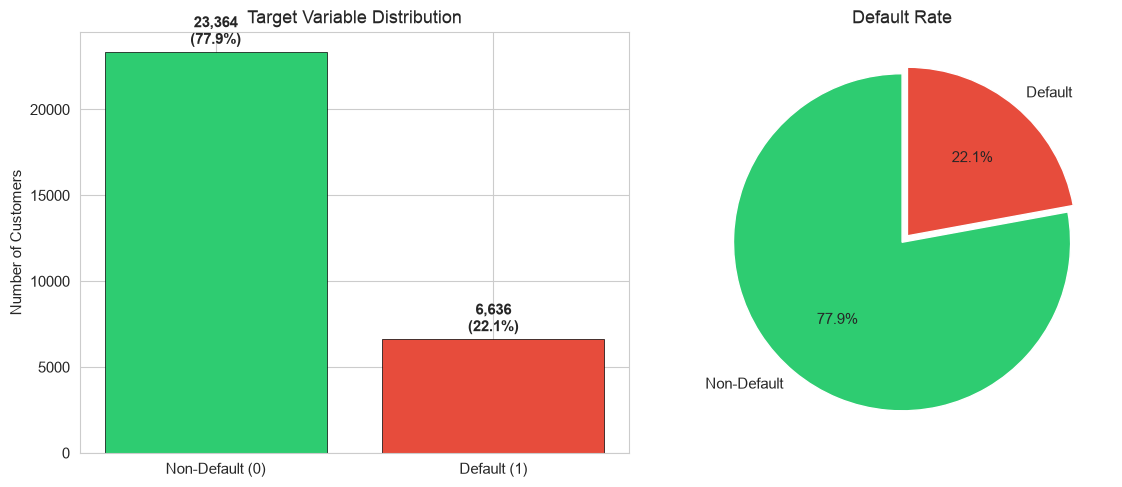

In [8]:
target_col = 'default payment next month'
default_counts = df[target_col].value_counts()
default_rate = df[target_col].mean()

print(f"Default rate: {default_rate:.4f} ({default_rate*100:.2f}%)")
print(f"Default (1): {default_counts[1]:,}")
print(f"Non-default (0): {default_counts[0]:,}")
print(f"Imbalance ratio: 1:{default_counts[0]/default_counts[1]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(['Non-Default (0)', 'Default (1)'],
                    [default_counts[0], default_counts[1]],
                    color=colors, edgecolor='black', linewidth=0.5)
for bar, count in zip(bars, [default_counts[0], default_counts[1]]):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 200,
                 f'{count:,}\n({count/len(df)*100:.1f}%)',
                 ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Target Variable Distribution')
axes[0].set_ylabel('Number of Customers')

# Pie chart
axes[1].pie([default_counts[0], default_counts[1]],
            labels=['Non-Default', 'Default'],
            colors=colors, autopct='%1.1f%%',
            startangle=90, explode=(0, 0.05))
axes[1].set_title('Default Rate')

plt.tight_layout()
plt.savefig('../reports/01_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 1.7 Segment Analysis with SQL (DuckDB)

We explore the data with SQL queries using DuckDB. This approach demonstrates the SQL-based analysis skills that are common in the banking sector.

In [9]:
con = duckdb.connect()
con.register('credit', df)

# Query 1: Default rate
print("=== Overall Default Distribution ===")
con.sql("""
    SELECT
        "default payment next month" AS default_flag,
        COUNT(*) AS n,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS pct
    FROM credit
    GROUP BY 1
    ORDER BY 1
""").show()

=== Overall Default Distribution ===
┌──────────────┬───────┬────────┐
│ default_flag │   n   │  pct   │
│    int64     │ int64 │ double │
├──────────────┼───────┼────────┤
│            0 │ 23364 │  77.88 │
│            1 │  6636 │  22.12 │
└──────────────┴───────┴────────┘



In [10]:
# Query 2: Default rate by gender
print("=== Default Rate by Gender ===")
con.sql("""
    SELECT
        CASE WHEN SEX = 1 THEN 'Male' ELSE 'Female' END AS gender,
        COUNT(*) AS n,
        SUM("default payment next month") AS default_count,
        ROUND(AVG("default payment next month") * 100, 2) AS default_rate_pct
    FROM credit
    GROUP BY SEX
    ORDER BY default_rate_pct DESC
""").show()

=== Default Rate by Gender ===
┌─────────┬───────┬───────────────┬──────────────────┐
│ gender  │   n   │ default_count │ default_rate_pct │
│ varchar │ int64 │    int128     │      double      │
├─────────┼───────┼───────────────┼──────────────────┤
│ Male    │ 11888 │          2873 │            24.17 │
│ Female  │ 18112 │          3763 │            20.78 │
└─────────┴───────┴───────────────┴──────────────────┘



In [11]:
# Query 3: Default rate by education level
print("=== Default Rate by Education Level ===")
con.sql("""
    SELECT
        CASE
            WHEN EDUCATION = 1 THEN '1-Graduate'
            WHEN EDUCATION = 2 THEN '2-University'
            WHEN EDUCATION = 3 THEN '3-High School'
            ELSE '4-Other'
        END AS education_level,
        COUNT(*) AS n,
        ROUND(AVG("default payment next month") * 100, 2) AS default_rate_pct,
        ROUND(AVG(LIMIT_BAL), 0) AS avg_limit
    FROM credit
    GROUP BY EDUCATION
    ORDER BY EDUCATION
""").show()

=== Default Rate by Education Level ===
┌─────────────────┬───────┬──────────────────┬───────────┐
│ education_level │   n   │ default_rate_pct │ avg_limit │
│     varchar     │ int64 │      double      │  double   │
├─────────────────┼───────┼──────────────────┼───────────┤
│ 4-Other         │    14 │              0.0 │  217143.0 │
│ 1-Graduate      │ 10585 │            19.23 │  212956.0 │
│ 2-University    │ 14030 │            23.73 │  147062.0 │
│ 3-High School   │  4917 │            25.16 │  126550.0 │
│ 4-Other         │   123 │             5.69 │  220894.0 │
│ 4-Other         │   280 │             6.43 │  168164.0 │
│ 4-Other         │    51 │            15.69 │  148235.0 │
└─────────────────┴───────┴──────────────────┴───────────┘



In [12]:
# Query 4: Default rate by credit limit band
print("=== Default Rate by Limit Band ===")
con.sql("""
    SELECT
        CASE
            WHEN LIMIT_BAL < 50000 THEN 'A: < 50K'
            WHEN LIMIT_BAL < 100000 THEN 'B: 50K-100K'
            WHEN LIMIT_BAL < 200000 THEN 'C: 100K-200K'
            WHEN LIMIT_BAL < 500000 THEN 'D: 200K-500K'
            ELSE 'E: 500K+'
        END AS limit_band,
        COUNT(*) AS n,
        ROUND(AVG("default payment next month") * 100, 2) AS default_rate_pct,
        ROUND(AVG(AGE), 1) AS avg_age
    FROM credit
    GROUP BY 1
    ORDER BY 1
""").show()

=== Default Rate by Limit Band ===
┌──────────────┬───────┬──────────────────┬─────────┐
│  limit_band  │   n   │ default_rate_pct │ avg_age │
│   varchar    │ int64 │      double      │ double  │
├──────────────┼───────┼──────────────────┼─────────┤
│ A: < 50K     │  4311 │            36.07 │    33.7 │
│ B: 50K-100K  │  7139 │            26.01 │    34.6 │
│ C: 100K-200K │  7400 │            20.77 │    35.2 │
│ D: 200K-500K │ 10222 │            15.49 │    36.8 │
│ E: 500K+     │   928 │            11.21 │    39.4 │
└──────────────┴───────┴──────────────────┴─────────┘



In [13]:
# Query 5: Default rate by age group
print("=== Default Rate by Age Group ===")
con.sql("""
    SELECT
        CASE
            WHEN AGE < 25 THEN '20-24'
            WHEN AGE < 30 THEN '25-29'
            WHEN AGE < 35 THEN '30-34'
            WHEN AGE < 40 THEN '35-39'
            WHEN AGE < 50 THEN '40-49'
            ELSE '50+'
        END AS age_group,
        COUNT(*) AS n,
        ROUND(AVG("default payment next month") * 100, 2) AS default_rate_pct,
        ROUND(AVG(LIMIT_BAL), 0) AS avg_limit
    FROM credit
    GROUP BY 1
    ORDER BY 1
""").show()

=== Default Rate by Age Group ===
┌───────────┬───────┬──────────────────┬───────────┐
│ age_group │   n   │ default_rate_pct │ avg_limit │
│  varchar  │ int64 │      double      │  double   │
├───────────┼───────┼──────────────────┼───────────┤
│ 20-24     │  2685 │            27.19 │   60968.0 │
│ 25-29     │  6933 │            21.16 │  148700.0 │
│ 30-34     │  6078 │            19.32 │  195719.0 │
│ 35-39     │  5160 │            21.36 │  198512.0 │
│ 40-49     │  6464 │            22.97 │  180786.0 │
│ 50+       │  2680 │             25.3 │  166937.0 │
└───────────┴───────┴──────────────────┴───────────┘



In [14]:
# Query 6: Relationship between payment delinquency status and default
print("=== Most Recent Month Delinquency Status (PAY_0) and Default ===")
con.sql("""
    SELECT
        PAY_0 AS delinquency_status,
        COUNT(*) AS n,
        ROUND(AVG("default payment next month") * 100, 2) AS default_rate_pct,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS population_pct
    FROM credit
    GROUP BY PAY_0
    ORDER BY PAY_0
""").show()

=== Most Recent Month Delinquency Status (PAY_0) and Default ===
┌────────────────────┬───────┬──────────────────┬────────────────┐
│ delinquency_status │   n   │ default_rate_pct │ population_pct │
│       int64        │ int64 │      double      │     double     │
├────────────────────┼───────┼──────────────────┼────────────────┤
│                 -2 │  2759 │            13.23 │            9.2 │
│                 -1 │  5686 │            16.78 │          18.95 │
│                  0 │ 14737 │            12.81 │          49.12 │
│                  1 │  3688 │            33.95 │          12.29 │
│                  2 │  2667 │            69.14 │           8.89 │
│                  3 │   322 │            75.78 │           1.07 │
│                  4 │    76 │            68.42 │           0.25 │
│                  5 │    26 │             50.0 │           0.09 │
│                  6 │    11 │            54.55 │           0.04 │
│                  7 │     9 │            77.78 │           0.03

In [15]:
# Query 7: Cross analysis - Limit band x Delinquency status
print("=== Limit Band x Most Recent Month Delinquency → Default Rate ===")
con.sql("""
    SELECT
        CASE
            WHEN LIMIT_BAL < 100000 THEN 'Low Limit'
            WHEN LIMIT_BAL < 300000 THEN 'Medium Limit'
            ELSE 'High Limit'
        END AS limit_band,
        CASE
            WHEN PAY_0 <= 0 THEN 'No Delinquency'
            WHEN PAY_0 = 1 THEN '1 Month Delinquent'
            ELSE '2+ Months Delinquent'
        END AS delinquency,
        COUNT(*) AS n,
        ROUND(AVG("default payment next month") * 100, 2) AS default_rate_pct
    FROM credit
    GROUP BY 1, 2
    ORDER BY 1, 2
""").show()

=== Limit Band x Most Recent Month Delinquency → Default Rate ===
┌──────────────┬──────────────────────┬───────┬──────────────────┐
│  limit_band  │     delinquency      │   n   │ default_rate_pct │
│   varchar    │       varchar        │ int64 │      double      │
├──────────────┼──────────────────────┼───────┼──────────────────┤
│ High Limit   │ 1 Month Delinquent   │   516 │            27.91 │
│ High Limit   │ 2+ Months Delinquent │   179 │            69.27 │
│ High Limit   │ No Delinquency       │  4422 │             9.77 │
│ Low Limit    │ 1 Month Delinquent   │  1623 │            40.48 │
│ Low Limit    │ 2+ Months Delinquent │  1848 │            70.08 │
│ Low Limit    │ No Delinquency       │  7979 │             18.3 │
│ Medium Limit │ 1 Month Delinquent   │  1549 │            29.12 │
│ Medium Limit │ 2+ Months Delinquent │  1103 │            68.72 │
│ Medium Limit │ No Delinquency       │ 10781 │             12.2 │
└──────────────┴──────────────────────┴───────┴────────────────

## 1.8 Distribution Plots

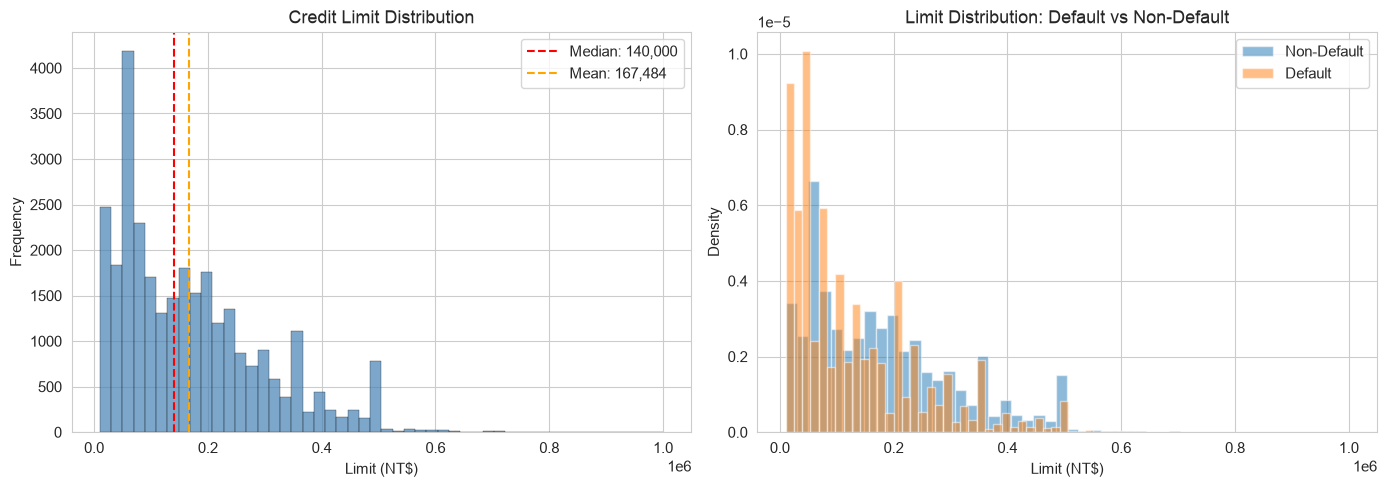

In [16]:
# Credit limit distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall distribution
axes[0].hist(df['LIMIT_BAL'], bins=50, color='steelblue', edgecolor='black', linewidth=0.3, alpha=0.7)
axes[0].axvline(df['LIMIT_BAL'].median(), color='red', linestyle='--', label=f"Median: {df['LIMIT_BAL'].median():,.0f}")
axes[0].axvline(df['LIMIT_BAL'].mean(), color='orange', linestyle='--', label=f"Mean: {df['LIMIT_BAL'].mean():,.0f}")
axes[0].set_title('Credit Limit Distribution')
axes[0].set_xlabel('Limit (NT$)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Comparison by default status
for label, group in df.groupby('default payment next month'):
    axes[1].hist(group['LIMIT_BAL'], bins=50, alpha=0.5,
                 label=f"{'Default' if label==1 else 'Non-Default'}",
                 density=True)
axes[1].set_title('Limit Distribution: Default vs Non-Default')
axes[1].set_xlabel('Limit (NT$)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.savefig('../reports/01_limit_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

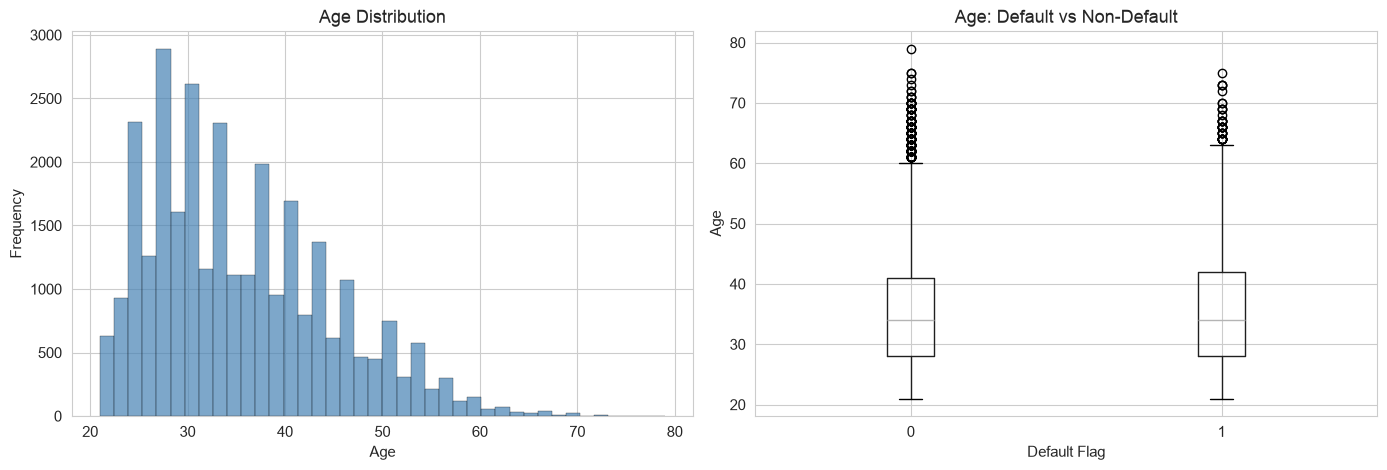

In [17]:
# Age distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['AGE'], bins=40, color='steelblue', edgecolor='black', linewidth=0.3, alpha=0.7)
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

# Age x Default boxplot
df.boxplot(column='AGE', by='default payment next month', ax=axes[1])
axes[1].set_title('Age: Default vs Non-Default')
axes[1].set_xlabel('Default Flag')
axes[1].set_ylabel('Age')
plt.suptitle('')

plt.tight_layout()
plt.savefig('../reports/01_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

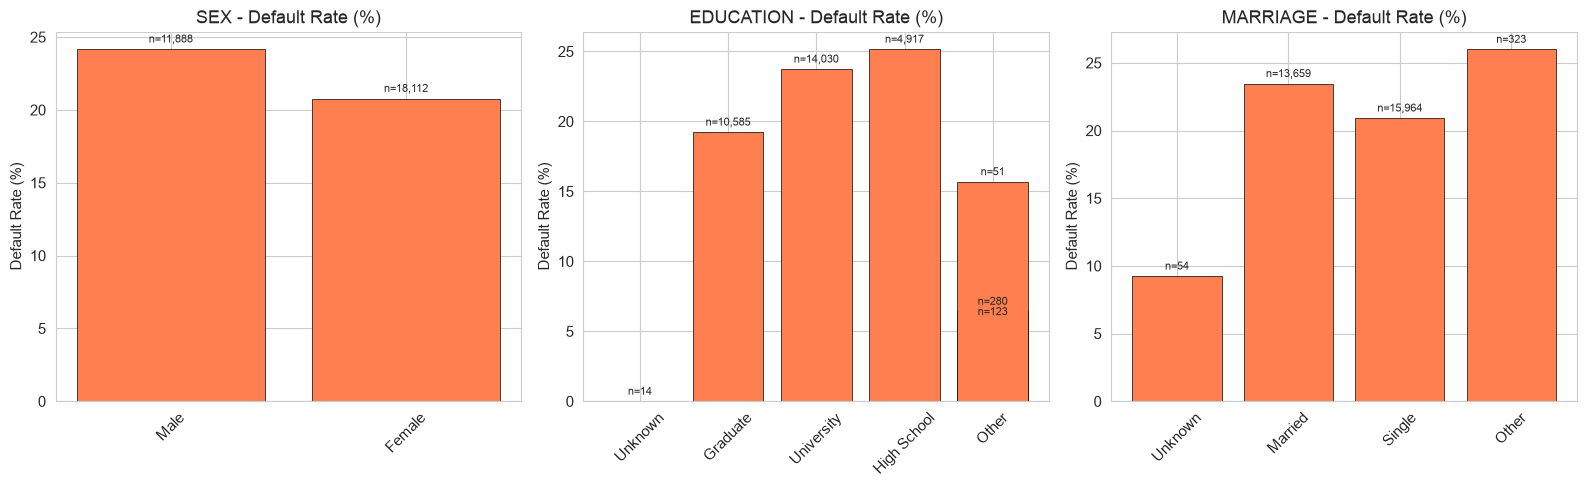

In [18]:
# Categorical variable distributions and default rates
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cat_vars = {
    'SEX': {1: 'Male', 2: 'Female'},
    'EDUCATION': {1: 'Graduate', 2: 'University', 3: 'High School', 4: 'Other', 5: 'Other', 6: 'Other', 0: 'Unknown'},
    'MARRIAGE': {1: 'Married', 2: 'Single', 3: 'Other', 0: 'Unknown'}
}

for idx, (var, mapping) in enumerate(cat_vars.items()):
    grouped = df.groupby(var)['default payment next month'].agg(['mean', 'count'])
    grouped.index = grouped.index.map(lambda x: mapping.get(x, f'Other ({x})'))

    bars = axes[idx].bar(grouped.index, grouped['mean'] * 100,
                         color='coral', edgecolor='black', linewidth=0.5)
    axes[idx].set_title(f'{var} - Default Rate (%)')
    axes[idx].set_ylabel('Default Rate (%)')
    axes[idx].tick_params(axis='x', rotation=45)

    for bar, (_, row) in zip(bars, grouped.iterrows()):
        axes[idx].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                       f'n={int(row["count"]):,}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('../reports/01_categorical_default_rates.png', dpi=150, bbox_inches='tight')
plt.show()

## 1.9 Payment History Analysis

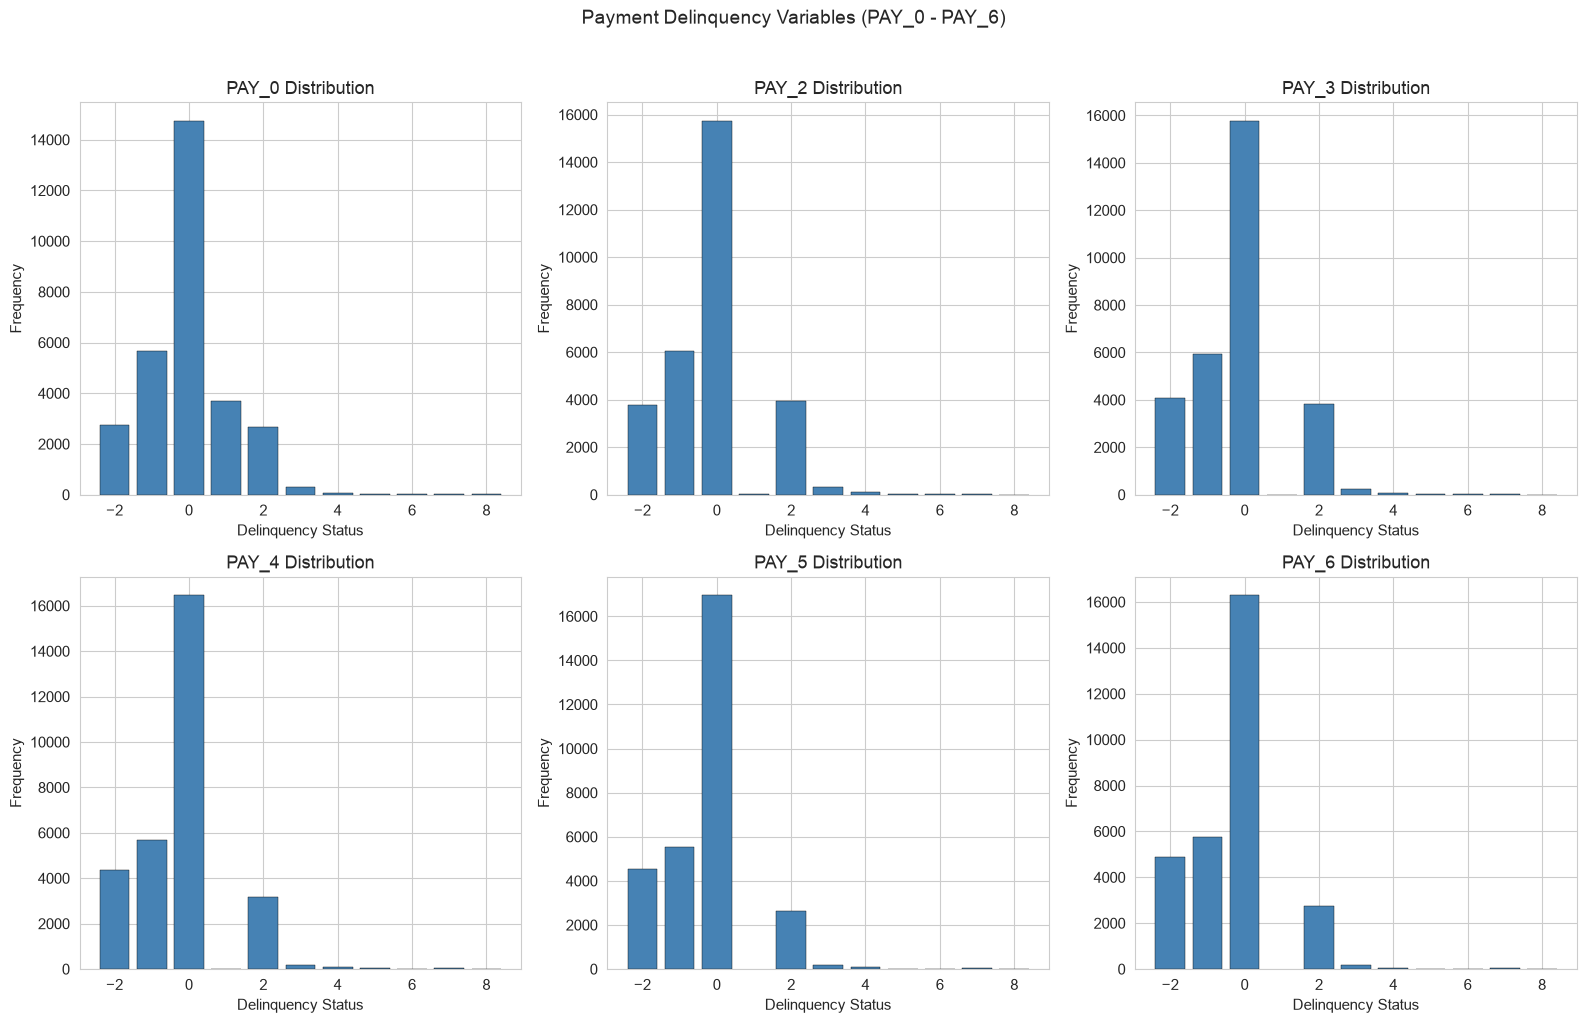

PAY_0 value descriptions:
  -2: Account not in use
  -1: Paid on time
   0: Minimum payment (revolver)
   1+: Delinquency duration (months)


In [19]:
# Distribution of the payment delinquency variables
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(pay_cols):
    vc = df[col].value_counts().sort_index()
    axes[idx].bar(vc.index, vc.values, color='steelblue', edgecolor='black', linewidth=0.3)
    axes[idx].set_title(f'{col} Distribution')
    axes[idx].set_xlabel('Delinquency Status')
    axes[idx].set_ylabel('Frequency')

plt.suptitle('Payment Delinquency Variables (PAY_0 - PAY_6)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../reports/01_payment_history.png', dpi=150, bbox_inches='tight')
plt.show()

# Note: -2=no account, -1=on time, 0=revolver, 1+=months delinquent
print("PAY_0 value descriptions:")
print("  -2: Account not in use")
print("  -1: Paid on time")
print("   0: Minimum payment (revolver)")
print("   1+: Delinquency duration (months)")

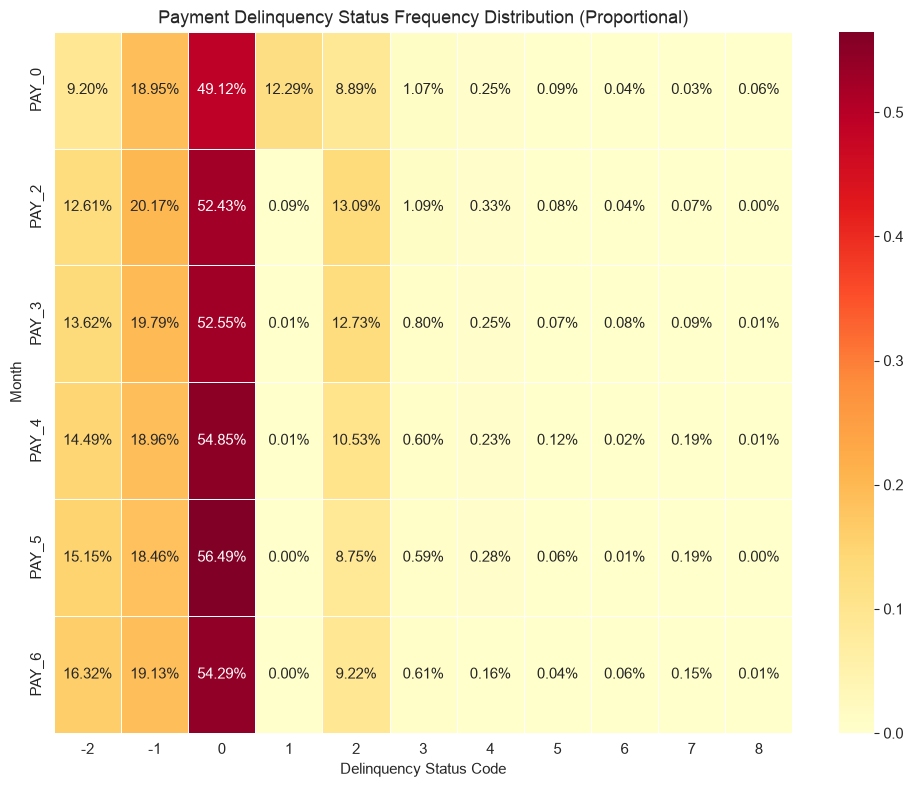

In [20]:
# Delinquency heatmap: each customer's 6-month delinquency profile
pay_data = df[pay_cols]

# Frequency of each delinquency status (cross-tabulation)
pay_freq = pd.DataFrame()
for col in pay_cols:
    pay_freq[col] = df[col].value_counts(normalize=True)
pay_freq = pay_freq.fillna(0).sort_index()

plt.figure(figsize=(10, 8))
sns.heatmap(pay_freq.T, annot=True, fmt='.2%', cmap='YlOrRd', linewidths=0.5)
plt.title('Payment Delinquency Status Frequency Distribution (Proportional)')
plt.xlabel('Delinquency Status Code')
plt.ylabel('Month')
plt.tight_layout()
plt.savefig('../reports/01_payment_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 1.10 Correlation Analysis

In [21]:
# Correlation with the target variable
target = 'default payment next month'
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop(['ID'])

corr_with_target = df[numeric_cols].corr()[target].drop(target).sort_values(ascending=False)
print("=== Correlations with the Target Variable (Pearson) ===")
print(corr_with_target.to_string())

=== Correlations with the Target Variable (Pearson) ===
PAY_0        0.32
PAY_2        0.26
PAY_3        0.24
PAY_4        0.22
PAY_5        0.20
PAY_6        0.19
EDUCATION    0.03
AGE          0.01
BILL_AMT6   -0.01
BILL_AMT5   -0.01
BILL_AMT4   -0.01
BILL_AMT3   -0.01
BILL_AMT2   -0.01
BILL_AMT1   -0.02
MARRIAGE    -0.02
SEX         -0.04
PAY_AMT6    -0.05
PAY_AMT5    -0.06
PAY_AMT3    -0.06
PAY_AMT4    -0.06
PAY_AMT2    -0.06
PAY_AMT1    -0.07
LIMIT_BAL   -0.15


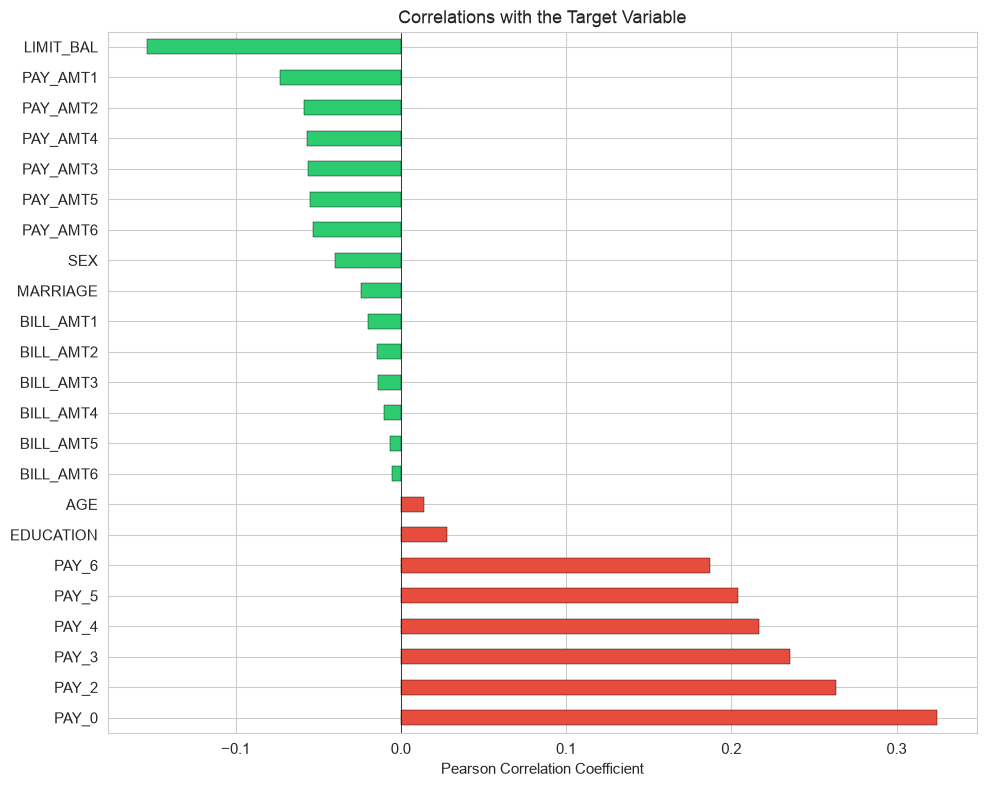

In [22]:
# Correlation bar plot
fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in corr_with_target.values]
corr_with_target.plot(kind='barh', ax=ax, color=colors, edgecolor='black', linewidth=0.3)
ax.set_title('Correlations with the Target Variable')
ax.set_xlabel('Pearson Correlation Coefficient')
ax.axvline(x=0, color='black', linewidth=0.5)
plt.tight_layout()
plt.savefig('../reports/01_correlation_target.png', dpi=150, bbox_inches='tight')
plt.show()

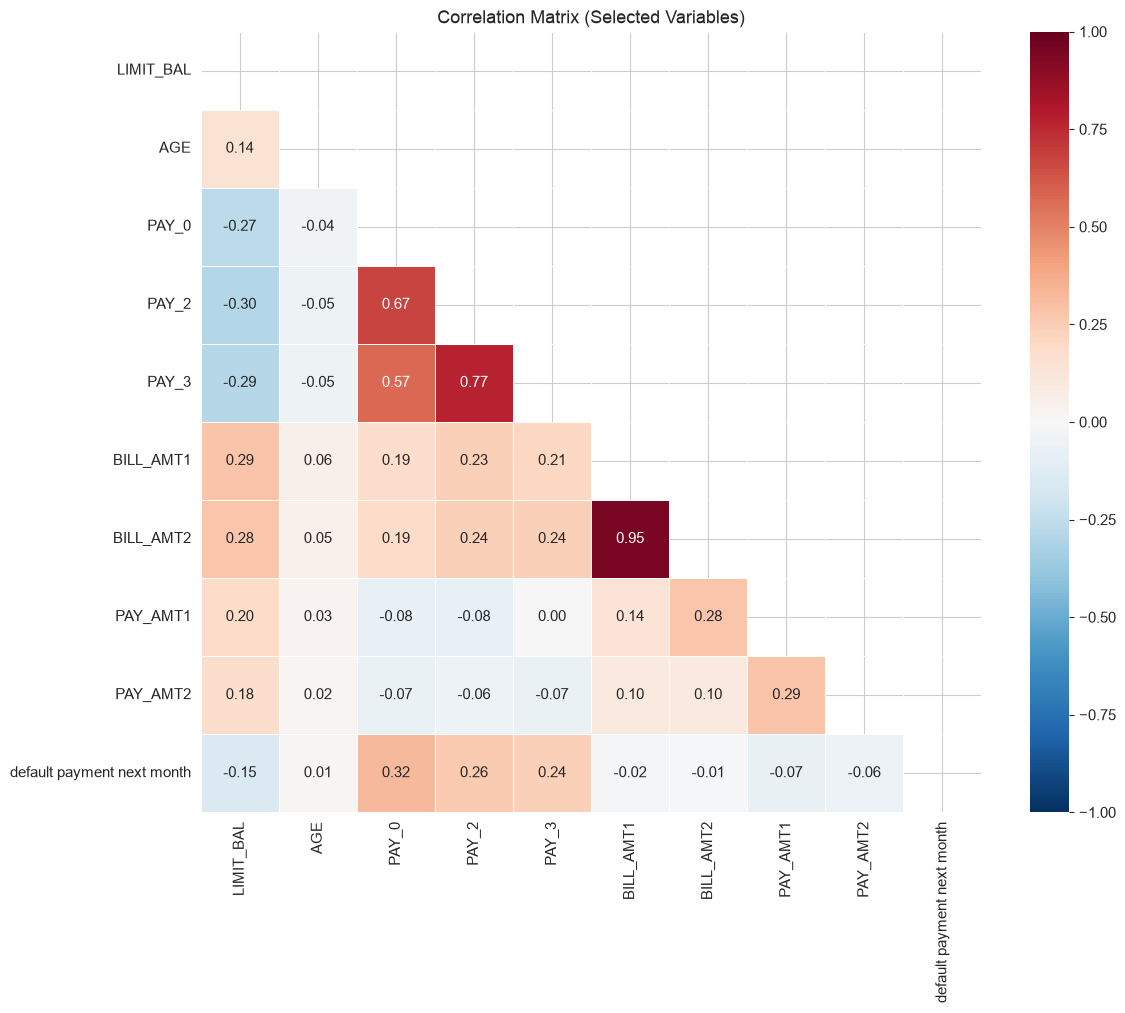

In [23]:
# Full correlation matrix (selected variables)
key_cols = ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3',
            'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_AMT2', target]

corr_matrix = df[key_cols].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True)
plt.title('Correlation Matrix (Selected Variables)')
plt.tight_layout()
plt.savefig('../reports/01_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 1.11 Outlier Analysis

In [24]:
# Outlier detection in continuous variables (IQR method)
continuous_vars = ['LIMIT_BAL', 'AGE'] + \
                  [f'BILL_AMT{i}' for i in range(1,7)] + \
                  [f'PAY_AMT{i}' for i in range(1,7)]

outlier_summary = []
for col in continuous_vars:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outlier Count': n_outliers,
        'Outlier Rate (%)': round(n_outliers / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Rate (%)
0,LIMIT_BAL,50000.00,240000.00,190000.00,-235000.00,525000.00,167,0.56
1,AGE,28.00,41.00,13.00,8.50,60.50,272,0.91
2,BILL_AMT1,3558.75,67091.00,63532.25,-91739.62,162389.38,2400,8.00
3,BILL_AMT2,2984.75,64006.25,61021.50,-88547.50,155538.50,2395,7.98
4,BILL_AMT3,2666.25,60164.75,57498.50,-83581.50,146412.50,2469,8.23
5,BILL_AMT4,2326.75,54506.00,52179.25,-75942.12,132774.88,2622,8.74
6,BILL_AMT5,1763.00,50190.50,48427.50,-70878.25,122831.75,2725,9.08
7,BILL_AMT6,1256.00,49198.25,47942.25,-70657.38,121111.62,2693,8.98
8,PAY_AMT1,1000.00,5006.00,4006.00,-5009.00,11015.00,2745,9.15
9,PAY_AMT2,833.00,5000.00,4167.00,-5417.50,11250.50,2714,9.05


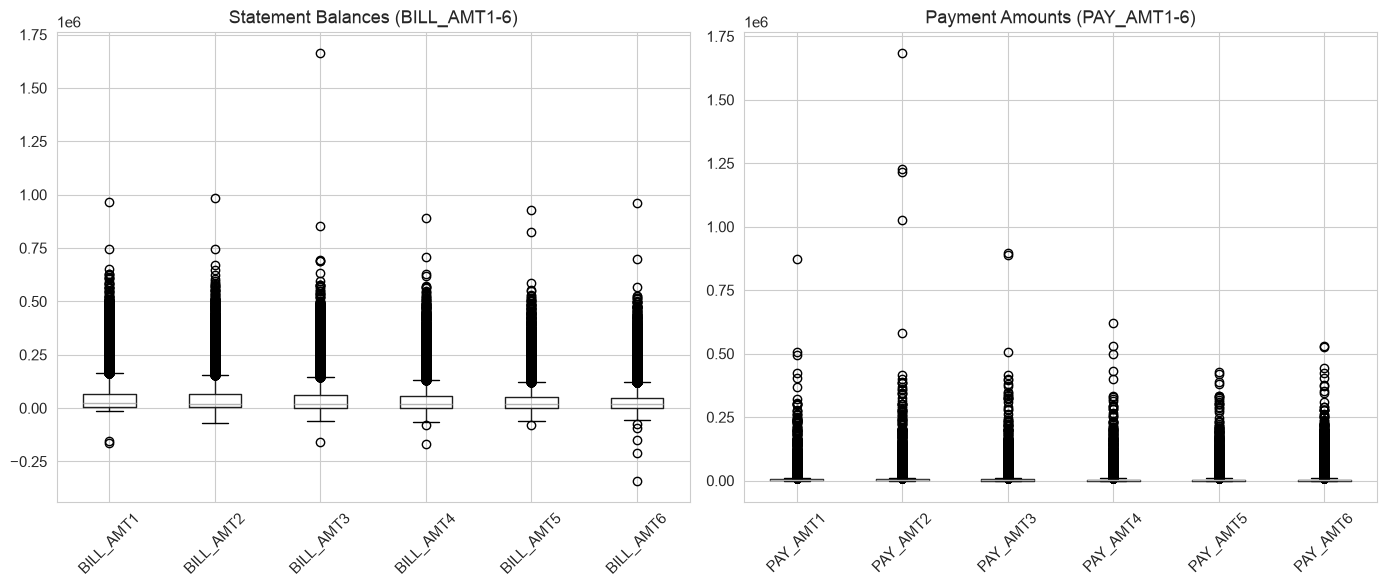

In [25]:
# Boxplot - Statement balances and payment amounts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

df[[f'BILL_AMT{i}' for i in range(1,7)]].boxplot(ax=axes[0])
axes[0].set_title('Statement Balances (BILL_AMT1-6)')
axes[0].tick_params(axis='x', rotation=45)

df[[f'PAY_AMT{i}' for i in range(1,7)]].boxplot(ax=axes[1])
axes[1].set_title('Payment Amounts (PAY_AMT1-6)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../reports/01_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

## 1.12 Data Quality Issues

In [26]:
# Check for undocumented values
print("=== Unexpected values in the EDUCATION variable ===")
print(df['EDUCATION'].value_counts().sort_index())
print("\nNote: values 0, 5 and 6 are undocumented. They will be merged into 'Other'.")

print("\n=== Unexpected values in the MARRIAGE variable ===")
print(df['MARRIAGE'].value_counts().sort_index())
print("\nNote: value 0 is undocumented. It will be treated as 'Other'.")

print("\n=== Value -2 in the PAY_0 variable ===")
print(f"Count of value -2: {(df['PAY_0'] == -2).sum():,}")
print("Note: -2 means 'account not in use'; -1 means paid on time.")

=== Unexpected values in the EDUCATION variable ===
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Note: values 0, 5 and 6 are undocumented. They will be merged into 'Other'.

=== Unexpected values in the MARRIAGE variable ===
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Note: value 0 is undocumented. It will be treated as 'Other'.

=== Value -2 in the PAY_0 variable ===
Count of value -2: 2,759
Note: -2 means 'account not in use'; -1 means paid on time.


## 1.13 Exploratory Analysis Summary

### Key Findings

1. **Data Quality:** There are no missing values, but the EDUCATION and MARRIAGE variables contain undocumented categories.
2. **Class Imbalance:** The default rate is ~22%; an imbalance strategy should be considered during modeling.
3. **Strong Signals:** PAY_0 (most recent month delinquency status) has the strongest correlation with the target variable.
4. **Limit and Default:** The default rate is markedly higher among customers with low limits.
5. **Outliers:** The BILL_AMT and PAY_AMT variables contain significant outliers.
6. **Multicollinearity:** The BILL_AMT variables are highly correlated with one another.

### Next Step
The feature engineering notebook will cover data cleaning, transformation and derived feature creation.